# Reconstrucción 3D
En este ejemplo estimamos la longitud de un objeto en milímetros. Hay tres vistas $p$, $q$ y $r$. El usuario proporciona dos puntos del objeto en cada vista. El código estima los dos puntos 3D y calcula la distancia 3D entre ellos. Dado que la calibración de este sistema de visión por computadora con rayos X se implementó utilizando un objeto de calibración con dimensiones medidas en milímetros, es claro que los puntos 3D reconstruidos también están dados en milímetros.

In [ ]:
# Load Images from GDxray dataset
!mkdir ~/GDXray
!mkdir ~/GDXray/Baggages

In [ ]:
!wget https://www.dropbox.com/s/swysmbjjuhnwpq6/B0044.zip
!unzip -oq B0044.zip  # Force to overwrite facilitates running the notebook without interactive actions
!rm B0044.zip
!rsync -av B0044 ~/GDXray/Baggages/

--2025-09-01 14:24:21--  https://www.dropbox.com/s/swysmbjjuhnwpq6/B0044.zip
Resolving www.dropbox.com (www.dropbox.com)... 162.125.6.18, 2620:100:6018:18::a27d:312
Connecting to www.dropbox.com (www.dropbox.com)|162.125.6.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/urajdt884bx83yhq8v6u3/B0044.zip?rlkey=tf9gy56amfx7txs2tyc208vly [following]
--2025-09-01 14:24:21--  https://www.dropbox.com/scl/fi/urajdt884bx83yhq8v6u3/B0044.zip?rlkey=tf9gy56amfx7txs2tyc208vly
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://ucd12f6a037068ab4270cb4f8c7f.dl.dropboxusercontent.com/cd/0/inline/CwivPR3ZhJpt91IWLQDpTmMSaB6gzkx3xJzxOPjGO2zXQuD1OOgp9TNGkTibS8Kr_9bOw2aVc_svJNRnd1dnrvTcNCVtXP6demFqKR2l-vFjQNfWrfa_5c_AudKyOtsi0xI/file# [following]
--2025-09-01 14:24:22--  https://ucd12f6a037068ab4270cb4f8c7f.dl.dropboxusercontent.com/cd/0/inline/CwivPR3ZhJpt91IWLQDpTmMSaB6gzkx

In [ ]:
# Load calibrated projection matrices
import scipy.io as sio
#!wget https://www.dropbox.com/s/es2k1qx1v6qle37/Pmatrices.mat
!wget https://www.dropbox.com/s/og4uhv0fo0qxdvn/Pmatrices.mat
data = sio.loadmat('Pmatrices.mat')

--2025-09-01 14:24:28--  https://www.dropbox.com/s/og4uhv0fo0qxdvn/Pmatrices.mat
Resolving www.dropbox.com (www.dropbox.com)... 162.125.6.18, 2620:100:6018:18::a27d:312
Connecting to www.dropbox.com (www.dropbox.com)|162.125.6.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/97syci7pvio9pbm14l8in/Pmatrices.mat?rlkey=o4jjbq8dhjtsa6paex0beiq3w [following]
--2025-09-01 14:24:29--  https://www.dropbox.com/scl/fi/97syci7pvio9pbm14l8in/Pmatrices.mat?rlkey=o4jjbq8dhjtsa6paex0beiq3w
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc2240dbc23656e3bae94f9cb76a.dl.dropboxusercontent.com/cd/0/inline/CwgxD4iCswRDRechBjS2gnMoHJyLKzKTHEzynuyZoZ1BAr-eA8spxPeSuqn3nV4bmX-wz-elpPLNnSmCmU5WGXjr4R21sdTvteD8SFmTBgwsfyZqRU_iTlWgwrzC4bO2x4o/file# [following]
--2025-09-01 14:24:29--  https://uc2240dbc23656e3bae94f9cb76a.dl.dropboxusercontent.com/cd/0/inline/CwgxD4iCswRDRechBjS

In [ ]:
def recon_3dn(m, mat_p, method=None):
    """
    This method computes the reconstruction of a M point from two dimensional
    points in images.

    Args:
        m:
        mat_p:
        method:
        ls: the function computes the reconstruction using least-square method

    Returns:
        mat_mr: Reprojected points
        ms: Estimated points in 2D
        err: reprojection error in pixels
    """

    n = m.shape[-1]

    mat_q = np.zeros((2 * n, 3))
    mat_r = np.zeros((2 * n, 1))

    for k in range(n):
        x = m[0, k] / m[2, k]
        y = m[1, k] / m[2, k]
        p = mat_p[k * 3:k * 3 + 3, :]
        mat_q[k * 2:k * 2 + 2, :] = np.array(
            [
                [p[2, 0] * x - p[0, 0], p[2, 1] * x - p[0, 1],
                 p[2, 2] * x - p[0, 2]],
                [p[2, 0] * y - p[1, 0], p[2, 1] * y - p[1, 1],
                 p[2, 2] * y - p[1, 2]]
            ]
        )

        mat_r[k * 2:k * 2 + 2, :] = np.array(
            [
                [p[0, 3] - p[2, 3] * x],
                [p[1, 3] - p[2, 3] * y]
            ]
        )

    mat_mr = np.vstack([np.dot(np.linalg.pinv(mat_q), mat_r), 1.0])  # Compute [Q.T * Q] * Q.T as pseudoinverse

    ms = mat_p @ mat_mr
    ms = np.reshape(ms, (n, 3)).T
    ms = ms / ms[-1, :]
    d = ms[0:1, :] - m[0:1, :]
    err = np.sqrt(np.sum(d * d, 1)).item()

    return mat_mr, ms, err


def num2fixstr(x,d):
  # example num2fixstr(2,5) returns '00002'
  # example num2fixstr(19,3) returns '019'
  st = '%0*d' % (d,x)
  return st


Projection Matrices:
P1 =  [[-7.96593955e+03 -1.20081318e+03  5.35587150e+00  1.29786479e+06]
 [-2.15860979e+01 -1.28491171e+03 -7.95823608e+03  1.06426593e+06]
 [-1.43537660e-02 -9.99895554e-01  1.68838178e-03  9.64055869e+02]]
P2 =  [[-2.83078450e+03  7.54220156e+03  5.35587150e+00  1.29786479e+06]
 [-1.26132131e+03 -2.46033776e+02 -7.95823608e+03  1.06426593e+06]
 [-9.81029753e-01 -1.93849874e-01  1.68838178e-03  9.64055869e+02]]
P3 =  [[ 7.91917914e+03  1.47808896e+03  5.35587150e+00  1.29786479e+06]
 [-2.32698237e+01  1.28488232e+03 -7.95823608e+03  1.06426593e+06]
 [-2.05508295e-02  9.99787384e-01  1.68838178e-03  9.64055869e+02]]
Object size: 45.5 mm


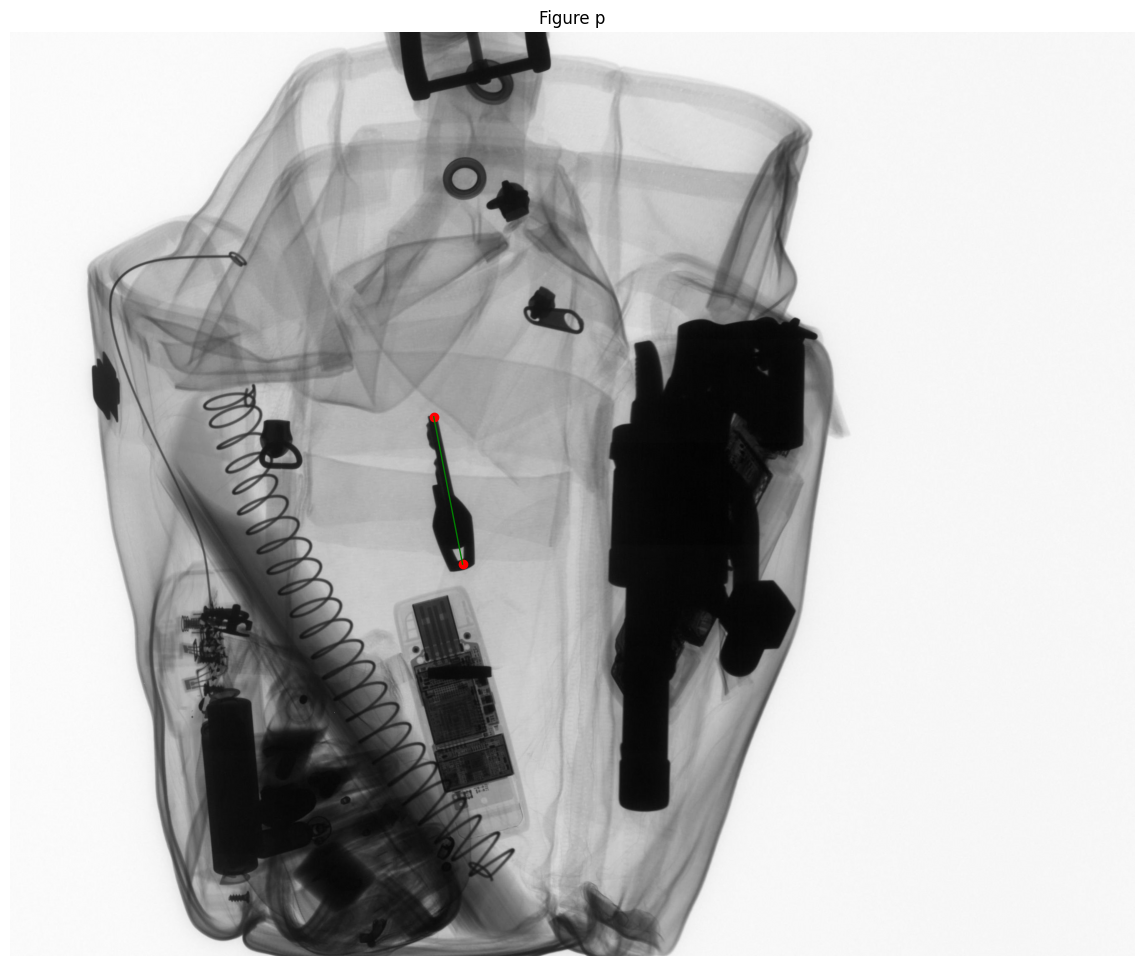

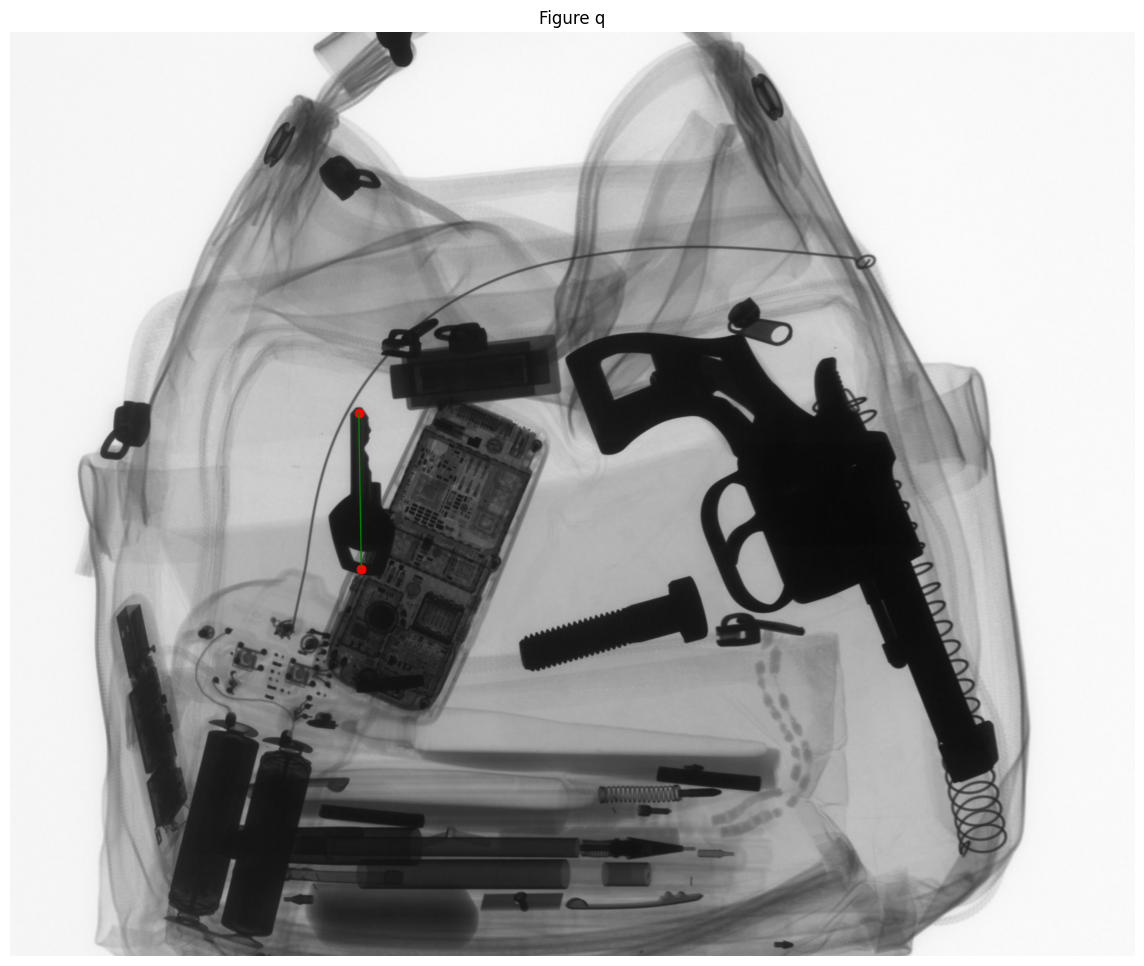

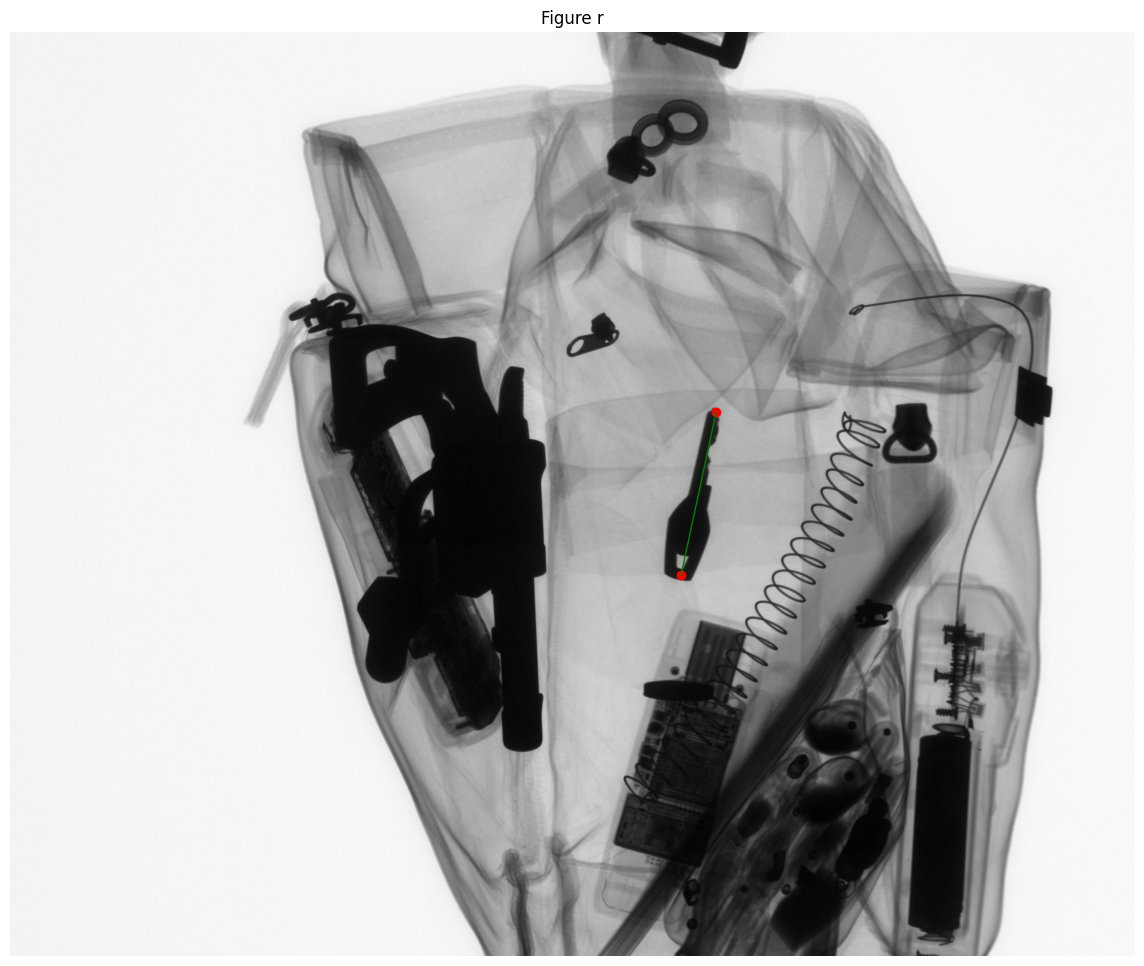

In [ ]:
import numpy as np
import matplotlib.pylab as plt
from cv2 import imread, IMREAD_GRAYSCALE


p, q, r = (1, 40, 90)  # indices for p, q and r

# Load projection matrices for views p, q, r
P1 = data['P'][:, :, p]  # Reprojection matrix of view p
P2 = data['P'][:, :, q]  # Reprojection matrix of view q
P3 = data['P'][:, :, r]  # Reprojection matrix of view r

print('Projection Matrices:')
print('P1 = ',P1)
print('P2 = ',P2)
print('P3 = ',P3)


P = np.vstack([P1, P2, P3])  # Join all projection matrices


Ip = imread('B0044/B0044_'+num2fixstr(p,4)+'.png', IMREAD_GRAYSCALE)
Iq = imread('B0044/B0044_'+num2fixstr(q,4)+'.png', IMREAD_GRAYSCALE)
Ir = imread('B0044/B0044_'+num2fixstr(r,4)+'.png', IMREAD_GRAYSCALE)


# Plot lines and plot on figures
fig1, ax1 = plt.subplots(1, 1, subplot_kw=dict(title='Figure p'),figsize=(18,12))
ax1.imshow(Ip, cmap='gray')
ax1.axis('off')

#print('Click first and second points in Figure 1 ...')
#mp = np.hstack([np.array(plt.ginput(2)), np.ones((2, 1))]).T  # Click
mp = np.ones((3,2))
mp[0,0] = 1012
mp[1,0] = 919
mp[0,1] = 1081
mp[1,1] = 1271

ax1.plot(mp[0, :], mp[1, :], 'ro')
ax1.plot(mp[0, :], mp[1, :], 'g', linewidth=1.0)
fig1.canvas.draw()

fig2, ax2 = plt.subplots(1, 1, subplot_kw=dict(title='Figure q'),figsize=(18,12))
ax2.imshow(Iq, cmap='gray')
ax2.axis('off')
#print('Click first and second points in Figure 2 ...')
#mq = np.hstack([np.array(plt.ginput(2)), np.ones((2, 1))]).T  # Click
mq = np.ones((3,2))
mq[0,0] = 833
mq[1,0] = 910
mq[0,1] = 839
mq[1,1] = 1283

ax2.plot(mq[0, :], mq[1, :], 'ro')
ax2.plot(mq[0, :], mq[1, :], 'g', linewidth=1.0)
fig2.canvas.draw()

fig3, ax3 = plt.subplots(1, 1, subplot_kw=dict(title='Figure r'),figsize=(18,12))
ax3.imshow(Ir, cmap='gray')
ax3.axis('off'),
#print('Click first and second points in Figure 3 ...')
#mr = np.hstack([np.array(plt.ginput(2)), np.ones((2, 1))]).T  # Click
mr = np.ones((3,2))
mr[0,0] = 1687
mr[1,0] = 907
mr[0,1] = 1603
mr[1,1] = 1298

ax3.plot(mr[0, :], mr[1, :], 'ro')
ax3.plot(mr[0, :], mr[1, :], 'g', linewidth=1.0)
fig3.canvas.draw()

# 3D reprojection
mm_1 = np.vstack([mp[:, 0], mq[:, 0], mr[:, 0]]).T  # First 2D point in each view
mm_2 = np.vstack([mp[:, 1], mq[:, 1], mr[:, 1]]).T  # Second 2D point in each view
M1, d1, err1 = recon_3dn(mm_1, P)  # 3D reconstruction of first point
M2, d2, err2 = recon_3dn(mm_2, P)  # 3D reconstruction of second point

Md = M1.ravel()[:-1] - M2.ravel()[:-1]  # 3D vector from 1stt to 2nd point
dist = np.linalg.norm(Md)  # length of 3D vector in mm

print(f'Object size: {dist:0.3} mm')

plt.show()


The output of this code is shown in the last three figures. The code uses the function of PyXvis: `reco_3dn` to compute the 3D reconstruction using:

$
{\bf \hat M} = [{\bf Q}^{\sf T} {\bf Q}]^{-1}{\bf Q}^{\sf T}{\bf r}.
$

The estimated length in this example was `dist = 45.5mm`. The reader that is interested in 3D reconstruction using equation:

$
{\bf M = H}^{-1}{\bf M'} = \alpha {\bf H}^{-1}
\left[\begin{array}{c}
(y_q b_{14} - x_q b_{24}){\bf m}_p\\
(x_q {\bf b}_2  - y_q {\bf b}_1 ){\bf m}_p\end{array} \right]
$

for two views can use command `reco_3d2` from PyXvis. More details in Section 3.6 of the Book.